# Punto 1: Antes de empacar

Mateo Caballero Serna, Lucian Valle Aguilar

¿Cuántos mosquitos traeremos después de cuatro noches en Cheté? Esta estimación se hizo sin ver los datos del estudio.

# Hipótesis

Imaginamos un pueblo rural pequeño junto al río Timbiquí, con zonas verdes, fuentes de agua cercanas, lluvias frecuentes y una temperatura entre 25 y 30 °C. La captura se hace con personas como cebo: cada colector aspira los zancudos que se le posan. Como solo las hembras buscan sangre (los machos se alimentan de néctar), casi todo lo que se captura son hembras.

En lugar de estimar cuántos mosquitos hay en todo el pueblo, que no se puede medir, partimos de cuántos zancudos se le posan a una persona por hora y lo ajustamos con 3 factores:

$m_{crianza}$: humedad, zonas húmedas, río y lluvias, que ayudan a que nazcan más mosquitos.

$m_{supervivencia}$: temperatura, depredadores y fumigación.

$m_{habitantes}$: personas y animales que sirven de alimento a los mosquitos.

Estos factores multiplican a

$r_{ref}$: número promedio de zancudos que se posan en una persona por hora en una zona rural de referencia.

Otros factores que tenemos en cuenta:

- $k_{intra}$: cuánto se captura adentro de la casa comparado con afuera.
- $f_{Anoph}$: fracción de los capturados que son *Anopheles*.

**Cómo organizaríamos la captura:** 4 noches, de 6:00 pm a 6:00 am (12 horas, con dos turnos de 6 horas), en 3 casas, con un colector adentro y otro afuera de cada casa. Eso da 4 × 12 × 3 × 2 = 288 persona-horas. Ponemos uno adentro y uno afuera para poder comparar los dos sitios en la misma casa, y no más de uno por sitio para que no compitan por los mismos mosquitos.

Los colectores guardan todo lo que se les posa y en el laboratorio se separa por género. Por eso calculamos el total capturado (para los frascos) y los *Anopheles* (para el estudio).

Se relacionan por medio de la siguiente expresión:

$$N_{total} = \underbrace{\text{NOCHES} \times \text{HORAS} \times N_{casas} \times (1 + k_{intra})}_{\text{esfuerzo}} \times \underbrace{r_{ref} \times m_{crianza} \times m_{supervivencia} \times m_{habitantes}}_{r:\ \text{tasa en Cheté}}$$

$$N_{Anoph} = N_{total} \times f_{Anoph}$$

# Valores escogidos

Cada rango es el valor bajo y el valor alto que nos parecen razonables. Los tomamos como los percentiles 5 y 95, es decir, creemos que hay un 90 % de probabilidad de que el valor real esté dentro.

$r_{ref}$: [1, 10]. Pensamos en una zona rural de tierra caliente, sin repelente: al anochecer se posan varios zancudos por hora, y menos el resto de la noche.

$m_{crianza}$: [1, 5]. Con el río al lado y lluvia constante es difícil que haya menos criaderos que en la zona de referencia, pero los charcos pueden multiplicarlos varias veces.

$m_{supervivencia}$: [0.5, 2]. La temperatura está cerca de la mejor para el mosquito (cerca de 25 °C según Mordecai et al., 2013), pero no sabemos si hay fumigación o depredadores, y los aguaceros fuertes también matan adultos.

$m_{habitantes}$: [0.5, 2]. No sabemos para dónde va: más gente atrae más mosquitos, pero también los reparte entre más personas.

$f_{Anoph}$: [0.1, 0.6]. Al cebo también llegan *Culex*, *Mansonia* y otros. Como es una fracción, usamos una distribución que no pase de 1 (logit-normal).

$k_{intra}$: [0.3, 1]. Suponemos que adentro se captura igual o menos que afuera, porque las casas son abiertas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.special import logit, expit

rng = np.random.default_rng(42)
M = 200_000
Z95 = norm.ppf(0.95)

NOCHES = 4
HORAS = 12
N_CASAS = 3
INTRA_POR_CASA = 1
PERI_POR_CASA = 1
CAPACIDAD_FRASCO = 50   # supuesto, por confirmar con el equipo

factores = {
    "r_ref":           (1.0, 10.0, "lognormal"),
    "m_crianza":       (1.0, 5.0,  "lognormal"),
    "m_supervivencia": (0.5, 2.0,  "lognormal"),
    "m_habitantes":    (0.5, 2.0,  "lognormal"),
    "k_intra":         (0.3, 1.0,  "lognormal"),
    "f_anoph":         (0.1, 0.6,  "logitnormal"),
}


def parametros(bajo, alto, tipo):
    g = np.log if tipo == "lognormal" else logit
    return 0.5 * (g(bajo) + g(alto)), (g(alto) - g(bajo)) / (2 * Z95)


def muestrear(bajo, alto, tipo, size):
    mu, sigma = parametros(bajo, alto, tipo)
    x = rng.normal(mu, sigma, size)
    return np.exp(x) if tipo == "lognormal" else expit(x)


def mediana(bajo, alto, tipo):
    mu, _ = parametros(bajo, alto, tipo)
    return np.exp(mu) if tipo == "lognormal" else expit(mu)


def modelo(s):
    r = s["r_ref"] * s["m_crianza"] * s["m_supervivencia"] * s["m_habitantes"]
    esfuerzo = NOCHES * HORAS * N_CASAS * (PERI_POR_CASA + INTRA_POR_CASA * s["k_intra"])
    n_total = esfuerzo * r
    return n_total, n_total * s["f_anoph"]


muestras = {k: muestrear(*v, M) for k, v in factores.items()}
N_total, N_anoph = modelo(muestras)
medianas = {k: mediana(*v) for k, v in factores.items()}

# sensibilidad: cuánta varianza de ln(N) se va si fijamos cada factor en su mediana
var_total = np.var(np.log(N_anoph))
contrib = {}
for k in factores:
    s = dict(muestras)
    s[k] = np.full(M, medianas[k])
    contrib[k] = 1 - np.var(np.log(modelo(s)[1])) / var_total
contrib = dict(sorted(contrib.items(), key=lambda kv: -kv[1]))

pt = np.percentile(N_total, [5, 50, 95])
pa = np.percentile(N_anoph, [5, 50, 95])
print(f"Persona-horas: {NOCHES * HORAS * N_CASAS * (INTRA_POR_CASA + PERI_POR_CASA)}")
print(f"Total capturado: mediana {pt[1]:,.0f}, rango 90 % [{pt[0]:,.0f}, {pt[2]:,.0f}]")
print(f"Anopheles:       mediana {pa[1]:,.0f}, rango 90 % [{pa[0]:,.0f}, {pa[2]:,.0f}]")
print(f"Frascos: {np.ceil(pt[1] / CAPACIDAD_FRASCO):.0f} para la mediana, {np.ceil(pt[2] / CAPACIDAD_FRASCO):.0f} para el p95")
print("\nContribución a la varianza:")
for k, c in contrib.items():
    print(f"  {k:<16} {100 * c:5.1f} %")

Persona-horas: 288
Total capturado: mediana 1,597, rango 90 % [284, 9,026]
Anopheles:       mediana 442, rango 90 % [61, 3,014]
Frascos: 32 para la mediana, 181 para el p95

Contribución a la varianza:
  r_ref             34.9 %
  f_anoph           21.6 %
  m_crianza         16.9 %
  m_habitantes      12.8 %
  m_supervivencia   12.7 %
  k_intra            1.2 %


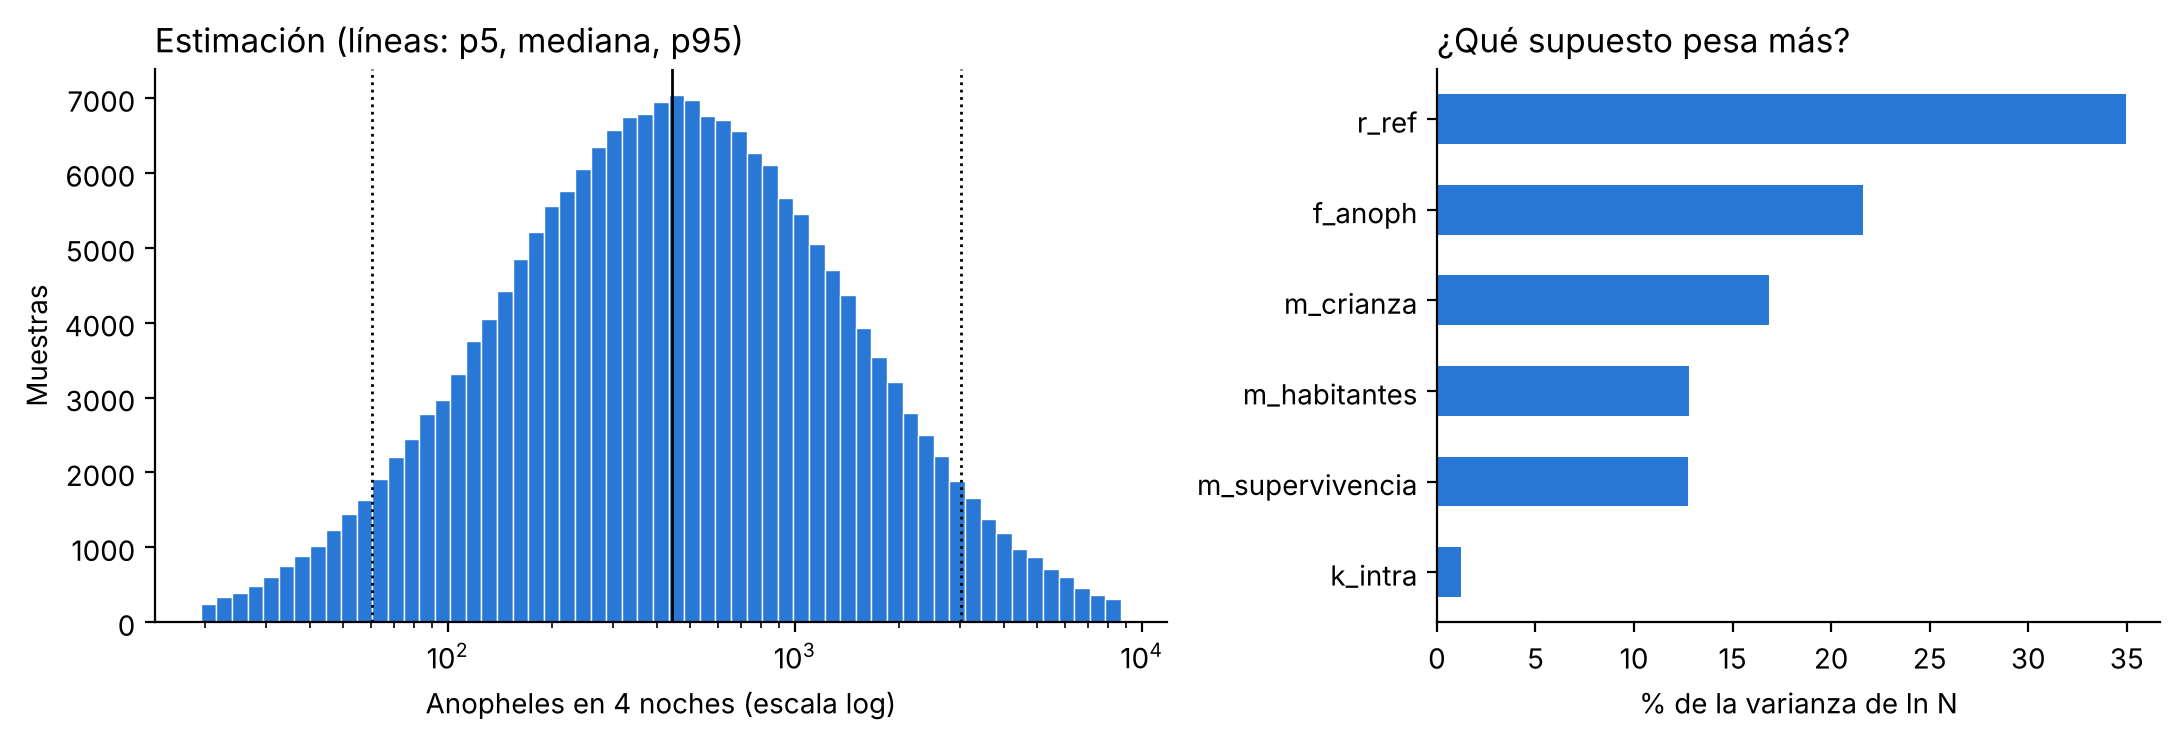

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
bins = np.logspace(np.log10(np.percentile(N_anoph, 0.5)), np.log10(np.percentile(N_anoph, 99.5)), 60)
ax1.hist(N_anoph, bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax1.set_xscale("log")
for p, ls in zip(pa, [":", "-", ":"]):
    ax1.axvline(p, color="black", lw=1, ls=ls)
ax1.set_xlabel("Anopheles en 4 noches (escala log)")
ax1.set_ylabel("Muestras")
ax1.set_title("Estimación (líneas: p5, mediana, p95)", loc="left")

nombres = list(contrib)[::-1]
ax2.barh(nombres, [100 * contrib[k] for k in nombres], color="#2a78d6", height=0.55)
ax2.set_xlabel("% de la varianza de ln N")
ax2.set_title("¿Qué supuesto pesa más?", loc="left")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figura_fermi.png", dpi=200, bbox_inches="tight")
plt.show()

# Resultado

Esperamos traer unos **440 *Anopheles*** en las 4 noches, con un rango de 90 % entre **61 y 3 014**. En total (todos los zancudos) serían unos 1 600, entre 284 y 9 026.

Para los frascos conviene planear con el valor alto y no con la mediana: si faltan frascos en campo no se pueden conseguir.

# Supuesto que más pesa

El que más mueve el resultado es $r_{ref}$, la tasa de referencia (35 % de la varianza), seguido de $f_{Anoph}$ y $m_{crianza}$. Es el primero que hay que comprobar en campo: después de la primera noche se dividen las capturas entre las persona-horas.

Con los datos solo se puede comprobar el producto de los factores (la tasa por persona-hora), no cada uno por separado.

**Limitaciones:** suponemos que todas las casas y todas las noches son iguales, y que los factores son independientes (aunque la lluvia afecta a la vez la crianza y la supervivencia).